# Training the model

Trains a model that predicts the AniList `mean_score` (0-100) of an anime using only
information available before its release.

1. Split the clean data into train (80%) and validation (20%).
2. Build one pipeline with all the preprocessing and the model.
3. Cross validate on train, fit, and save the pipeline to `model/pipe.joblib`.
4. Evaluate on validation.

Needs `data/train/anime_clean.csv`, created by `clean.ju.py`.

## Setup

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("../data/train/anime_clean.csv", encoding="utf-8")

## Label and features

`mean_score` is the label, every other column is a feature.

In [3]:
label = df.columns.str.contains("mean_score")
y = df.loc[:, label]
X = df.loc[:, ~label]

## Train / validation split

Random 80/20 split: 10,883 entries to train and 2,721 to validate.

The validation set was used to confirm the decisions taken with cross validation
(thresholds, encodings, which columns to drop), so its scores are probably a bit
optimistic. The untouched set is the 2026 one, used in `test.ju.py`.

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=17
)

# from a one column DataFrame to a Series
y_train = y_train.squeeze()
y_val = y_val.squeeze()

## Preprocessing

Everything that is learned from the data (medians, which tags are frequent)
is inside the pipeline. That way it is fitted only with the train set, or with the
train folds during cross validation, and nothing leaks from validation or test. At
first some of these steps were done before splitting; moving them here was the fix.

The custom transformers are in `anime_transformers.py`. The steps, in order:

| step | what it does |
|---|---|
| `impute` | fills nan `episode_duration_min` with the median of its `type` |
| `genres` | one column per genre (`genre_*`) |
| `onehot` | one-hot of `type`, `source` and `release_season` |
| `tags` | one column per tag seen at least 150 times (`tag_*`), plus `tag_other` and `tag_size` |
| `studios` | one column per main studio seen at least 40 times (`studio_*`), plus `studio_other` and `studio_size` |
| `staff` | `staff_wellknown` (someone with 50 or more entries), `staff_other` or `staff_unknown` (nan) |

- `*_other` is 1 when the anime has at least one tag/studio below the threshold.
- `*_size` is the number of train entries of its most frequent tag/studio.

The thresholds started lower, just enough entries for a value to carry information.
A lot of tags turned out not to carry much, so raising the threshold improved the
model. Different encodings were compared with the cross validation RMSE and the best
one was `other` + `size` for both tags and studios, with thresholds of 150 and 40.

The numeric columns are not scaled: the model is made of decision trees, which only
care about the order of the values.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
sys.path.append("..")
from anime_transformers import MedianByTypeImputer, MultiLabelEncoder, StaffEncoder

# categorical columns with a single value per anime
hot_cols = ["type", "source", "release_season"]

# columns not listed are passed as they are (remainder="passthrough")
# a category never seen in train becomes all zeros instead of an error
one_hot = ColumnTransformer(
    [
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         hot_cols)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

prep = Pipeline([
    ("impute", MedianByTypeImputer()),
    ("genres", MultiLabelEncoder("genres", "genre", min_count=1)),
    ("onehot", one_hot),
    ("tags", MultiLabelEncoder("tags", "tag", min_count=150, add_other=True, add_size=True)),
    ("studios",
     MultiLabelEncoder(
        "main_studios", "studio", min_count=40, add_other=True, add_size=True
     )
    ),
    ("staff", StaffEncoder("main_staff", "staff", min_count=50)),
])

## Model

`HistGradientBoostingRegressor`. How it was chosen:

- **Linear regression** was the first try, with a pretty bad performance.
- **Random forest** got an impressive RMSE in train (~4) that was not reflected in
  validation. Grid searches to reduce the overfitting did not improve it enough.
- **HistGradientBoostingRegressor** improved the predictions immediately. Its
  hyperparameters come from a grid search.

A dummy regressor was also tested to verify that the features were really giving
information: it was clearly worse than the model.

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score

pipe = Pipeline([
    ("prep", prep),
    ("model", HistGradientBoostingRegressor(
        random_state=17, learning_rate=0.05, max_iter=800, early_stopping=False
    )),
])

## Cross validation

5 folds over the train set. The mean RMSE of the folds is the number that was used to
compare every idea (thresholds, encodings, dropping columns) before confirming it
with the validation set.

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=17)

cvs = -cross_val_score(pipe, X_train, y_train, cv=kf,
                       scoring="neg_root_mean_squared_error")

print(cvs.round(3), "mean:", cvs.mean().round(5))

[7.268 6.981 7.02  7.128 7.213] mean: 7.12183


## Fit and save

The whole pipeline (preprocessing + model) is saved, so `test.ju.py` only has to load
it and predict from a clean csv.

In [8]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('genres', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,column,'episode_duration_min'
,type_column,'type'
Name,Type,Value


In [9]:
import joblib
joblib.dump(pipe, "../model/pipe.joblib")

['../model/pipe.joblib']

## Validation

### Scores

In [10]:
pred = pipe.predict(X_val)

In [11]:
# difference > 0: the real score was higher than the predicted one
comparison = pd.DataFrame({
    "real": y_val, "predicted": pred, "difference": y_val - pred
})

In [12]:
mse = mean_squared_error(y_val, pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_val, pred)

# MSE, RMSE and MAE, the last two are in score points (0-100)
print(mse)
print(rmse)
print(mae)

48.3456174424931
6.953101282341075
5.2408245076463045


### Distribution of the errors

Histogram of `real - predicted`, with its mean and 1, 2 and 3 standard deviations.
Saved as `images/hist_val.png`.

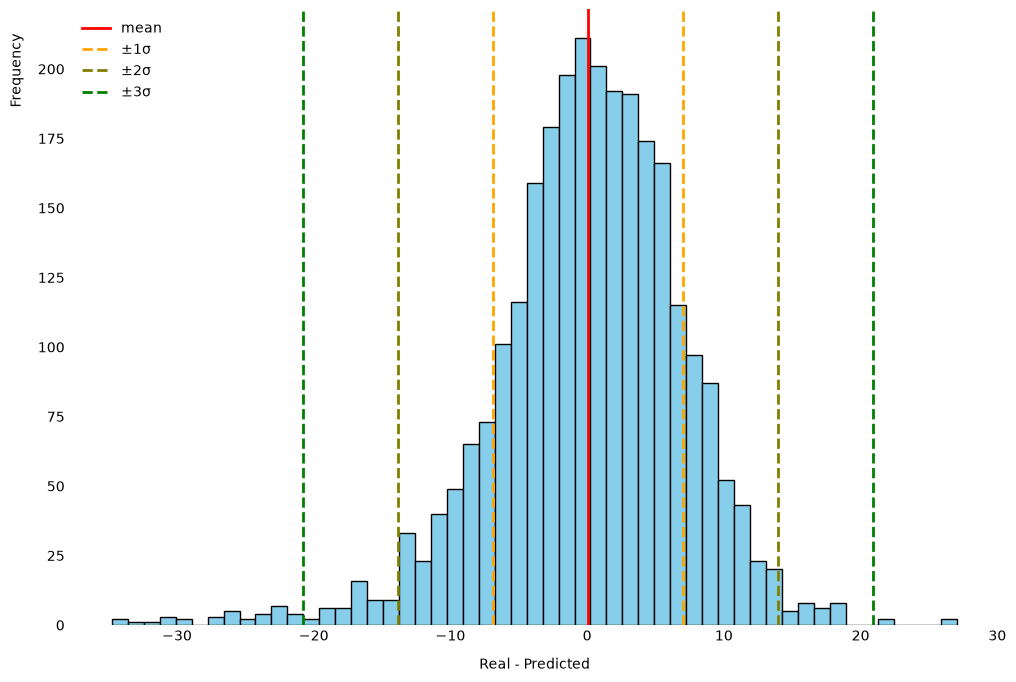

In [13]:
plt.figure(figsize=(12, 8))

plt.hist(comparison["difference"], bins="auto", color="skyblue", edgecolor="black")

mean = comparison["difference"].mean()
std = comparison["difference"].std()

plt.axvline(mean, color="#FF0000", linestyle="-", label="mean", linewidth=2)
plt.axvline(mean + std, color="#FFA500", linestyle="--", label="±1σ", linewidth=2)
plt.axvline(mean - std, color="#FFA500", linestyle="--", linewidth=2)
plt.axvline(mean + 2*std, color="#808000", linestyle="--", label="±2σ", linewidth=2)
plt.axvline(mean - 2*std, color="#808000", linestyle="--", linewidth=2)
plt.axvline(mean + 3*std, color="#008000", linestyle="--", label="±3σ", linewidth=2)
plt.axvline(mean - 3*std, color="#008000", linestyle="--", linewidth=2)

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.ylabel("Frequency", labelpad=10, fontsize=10, y=0.9)
plt.xlabel("Real - Predicted", labelpad=10, fontsize=10)

plt.legend(frameon=False, loc="upper left")
plt.show()

### Outliers

Box plot of the same differences, the red points are the outliers.
Saved as `images/box_val.png`.

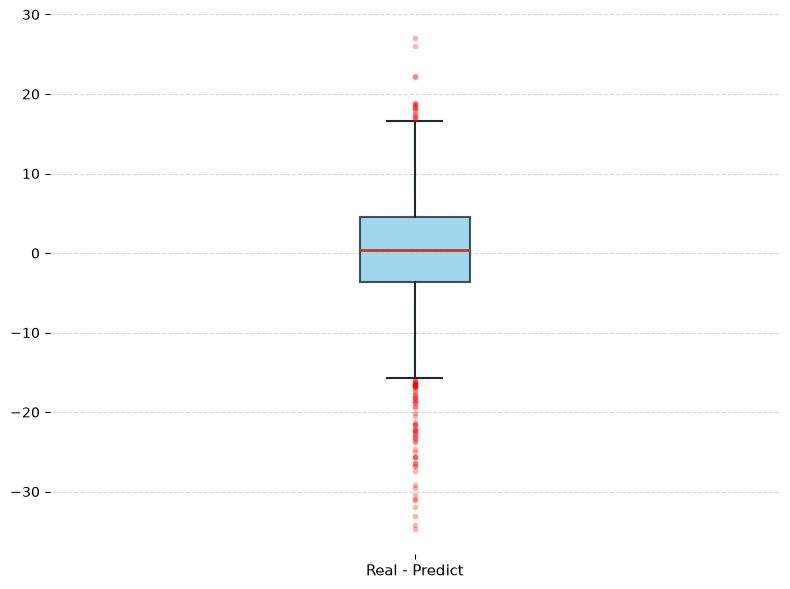

In [14]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

flier_style = dict(
    marker="o",
    markerfacecolor="red",
    markeredgecolor="none",
    markersize=4,
    alpha=0.3,
)

box_style = dict(facecolor="skyblue", edgecolor="#1C2833", alpha=0.8, linewidth=1.5)
median_style = dict(color="#C0392B", linewidth=2)
whisker_style = dict(color="#1C2833", linewidth=1.5)

bp = ax.boxplot(
    comparison["difference"],
    patch_artist=True,
    flierprops=flier_style,
    boxprops=box_style,
    medianprops=median_style,
    whiskerprops=whisker_style,
    capprops=whisker_style,
    orientation="vertical",
)

ax.set_xticklabels(["Real - Predict"], fontsize=11)

for side in ["top", "bottom", "left", "right"]:
    ax.spines[side].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()